## Plotagem de Gráficos

## Gráfico de Pizza
Vamos começar criando um gráfico de pizza para analisar as mortes causadas pelo vírus Ebola em países da África. O primeiro passo é importar as bibliotecas que serão utilizadas.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

A seguir, vamos fazer o upload do csv que contém os dados.

In [2]:
df = pd.read_csv('ebola.csv', encoding = 'latin-1')

In [3]:
df.head()

,Countries,Type,Number_of_cases,Death
0,Guinea,comfirmed cases,3351,2083
1,Guinea,Probable cases,453,453
2,Sierra Leone,comfirmed cases,8704,3589
3,Sierra Leone,Probable cases,287,208
4,Sierra Leone,Suspected cases,5131,158


Agora vamos filtrar apenas os dados de Sierra Leone.

In [4]:
sierra = df[df['Countries'] == 'Sierra Leone']
sierra

,Countries,Type,Number_of_cases,Death
2,Sierra Leone,comfirmed cases,8704,3589
3,Sierra Leone,Probable cases,287,208
4,Sierra Leone,Suspected cases,5131,158


Agora vamos gerar o gráfico de pizza de mortes por casos confirmados, prováveis e suspeitos. O primeiro passo é definir em qual coluna estão os dados (sizes - tamanhos do pedaço de pizza), e os rótulos (labels) de cada pedaço da pizza.

In [7]:
sizes = sierra['Death']
labels = sierra['Type']

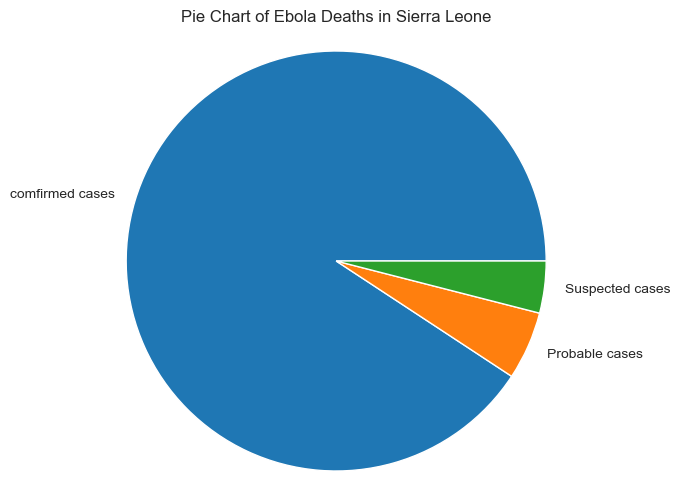

In [8]:
plt.rcParams['figure.figsize'] = [8,6]
sns.set_style('darkgrid')
plt.pie(sizes, labels = labels)
plt.title('Pie Chart of Ebola Deaths in Sierra Leone')
plt.axis('equal')
plt.show()

Podemos melhorar esse gráfico, mostrando a porcentagem de cada fatia (autopct='%1.1f%%), colocando uma sombra (shadow=True) e mudando o arranjo das fatias de pizza (startangle=90)

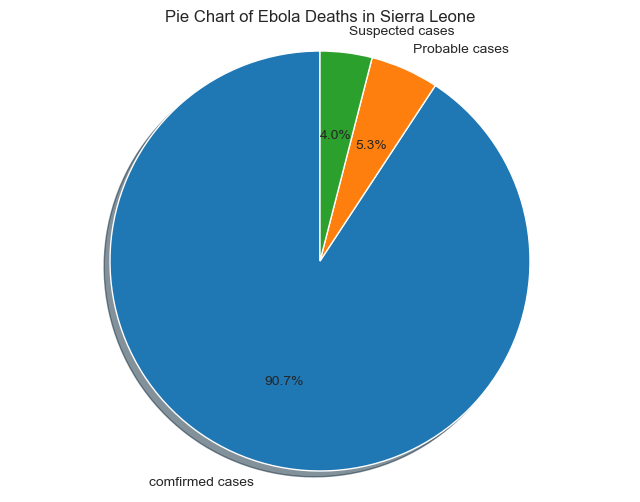

In [9]:
plt.pie(sizes, labels = labels, autopct = '%1.1f%%', shadow = True, startangle = 90), 
plt.title('Pie Chart of Ebola Deaths in Sierra Leone')
plt.axis('equal')
plt.show()

## Gráfico de pizza lado a lado
Para comparar dois gráficos de pizza é interessante plotá-los lado a lado. Vamos usar o dataframe Ebola para comparar os dados de Guinea e Sierra Leone.

Já temos os um dataframe com os dados de Sierra Leone. Vamos criar um dataframe para armazenar os dados de Guinea.

In [11]:

guinea = df[df['Countries'] == 'Guinea']
guinea

,Countries,Type,Number_of_cases,Death
0,Guinea,comfirmed cases,3351,2083
1,Guinea,Probable cases,453,453


Vamos agora definir o tamanho do nosso gráfico em 12x8.

In [13]:
plt.rcParams['figure.figsize'] = [12, 8]

Vamos agora definir sizes e labels para os dois gráficos. 

In [15]:
sizes_sierra = sierra['Death']
labels_sierra = sierra['Type']
sizes_guinea = guinea['Death']
labels_guinea = guinea['Type']


Agora vamos plotar os gráficos usando plt.subplot(lin, col, pos).

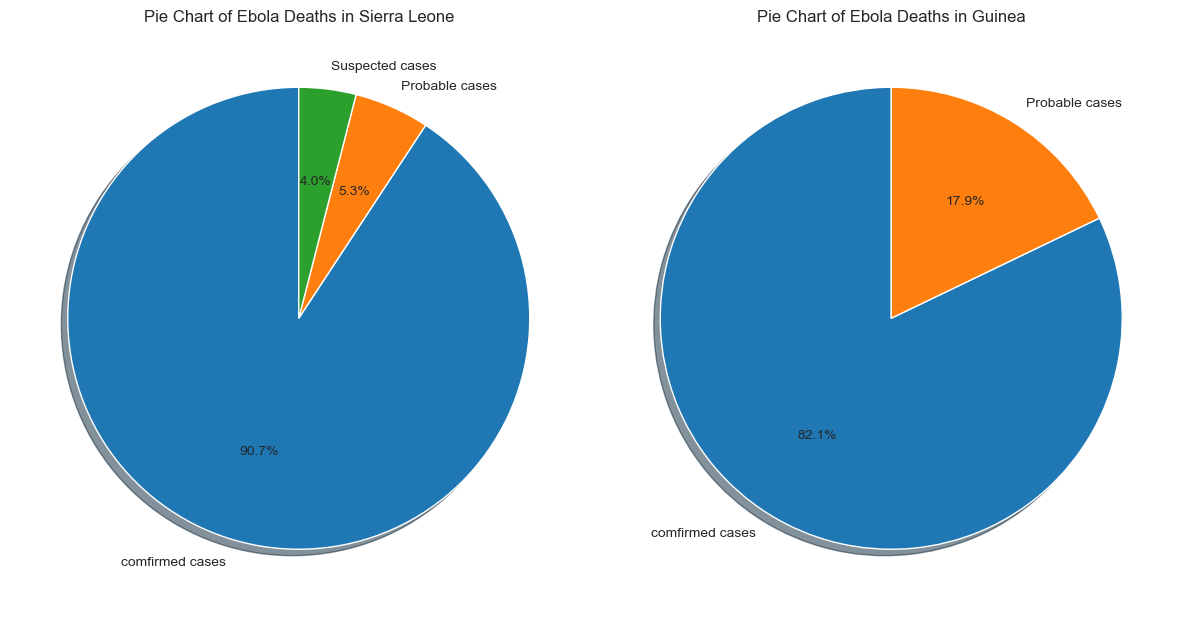

In [21]:
plt.subplot(1, 2, 1)
plt.pie(sizes_sierra, labels = labels_sierra, autopct = '%1.1f%%', shadow = True, startangle = 90), 
plt.title('Pie Chart of Ebola Deaths in Sierra Leone')
plt.subplot(1, 2, 2)
plt.pie(sizes_guinea, labels = labels_guinea, autopct = '%1.1f%%', shadow = True, startangle = 90), 
plt.title('Pie Chart of Ebola Deaths in Guinea')
plt.tight_layout()
plt.show()


### Exercício
Considere o dataset survey2021, que contém as respostas de um questionário respondido por desenvolvedores do software sobre suas atuações profissionais. 

In [22]:
df = pd.read_csv('survey2021.csv')
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 83439 entries, 0 to 83438
Data columns (total 48 columns):
 #   Column                        Non-Null Count  Dtype  
---  ------                        --------------  -----  
 0   ResponseId                    83439 non-null  int64  
 1   MainBranch                    83439 non-null  object 
 2   Employment                    83323 non-null  object 
 3   Country                       83439 non-null  object 
 4   US_State                      14920 non-null  object 
 5   UK_Country                    4418 non-null   object 
 6   EdLevel                       83126 non-null  object 
 7   Age1stCode                    83243 non-null  object 
 8   LearnCode                     82963 non-null  object 
 9   YearsCode                     81641 non-null  object 
 10  YearsCodePro                  61216 non-null  object 
 11  DevType                       66484 non-null  object 
 12  OrgSize                       60726 non-null  object 
 13  C

Vamos usar a coluna *LanguageHaveWorkedWith* para saber quais as linguagens de programação mais populares em 2021.

In [23]:
df['LanguageHaveWorkedWith']

0        C++;HTML/CSS;JavaScript;Objective-C;PHP;Swift
1                                    JavaScript;Python
2                             Assembly;C;Python;R;Rust
3                                JavaScript;TypeScript
4                       Bash/Shell;HTML/CSS;Python;SQL
                             ...                      
83434                               Clojure;Kotlin;SQL
83435                                              NaN
83436                               Groovy;Java;Python
83437             Bash/Shell;JavaScript;Node.js;Python
83438           Delphi;Elixir;HTML/CSS;Java;JavaScript
Name: LanguageHaveWorkedWith, Length: 83439, dtype: object

Temos que *LanguageHaveWorkedWith* possui 82.357 registros não nulos, ou seja, 82.357 declararam que trabalharam com alguma linguagem de programação. Note que a maioria trabalhou com 2 ou mais linguagens. Queremos saber o número de pessoas que trabalharam com Python, Javascript, Node.js, Java e SQL, bem como o número de pessoas que não trabalharam com nenhuma dessas linguagens.

Para isso, utilizaremos o método `str.contains` do Pandas (usado para verificar se um padrão ou texto está contido em uma string de uma Series). Em nosso exemplo, a lista de linguagens constitui o padrão. Em seguida, aplicaremos esse padrão ao DataFrame e obteremos as dimensões (*shape*) correspondentes a cada linguagem.

In [31]:
ling_list = ['Python', 'SQL', 'JavaScript', 'Node.js', 'C++']
for item in ling_list:
    filt = df['LanguageHaveWorkedWith'].str.contains(item, na = False)
    print(item, ':', df.loc[filt, 'LanguageHaveWorkedWith'].shape)

Python : (39792,)
SQL : (38835,)
JavaScript : (53587,)
Node.js : (27975,)
C++ : (64021,)


Agora podemos criar nosso gráfico de pizza e mostrar as linguagens de programação mais populares em 2021.

In [34]:
labels = ['Python', 'SQL', 'JavaScript', 'Node.js', 'C++']
sizes = [39792, 38835, 53587, 27975, 64021]
plt.rcParams['figure.figsize'] = [8, 6]

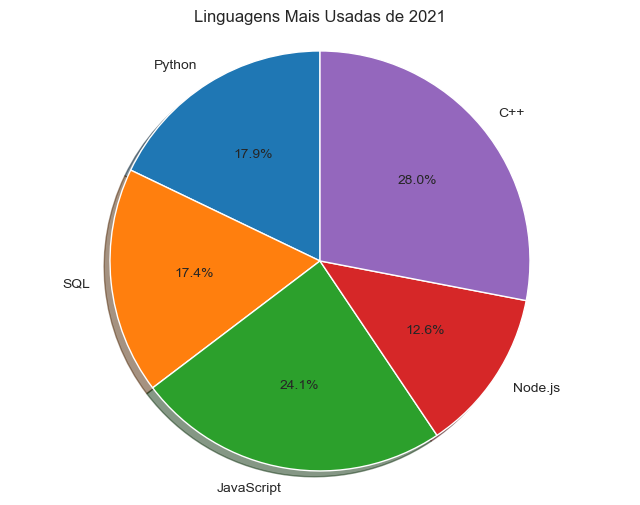

In [33]:
plt.pie(sizes, labels = labels, autopct = '%1.1f%%', shadow = True, startangle = 90)
plt.title('Linguagens Mais Usadas de 2021')
plt.axis('equal')
plt.show()